In [37]:
import utils
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from mne import (
    set_log_level,
    read_epochs,
    concatenate_epochs
)
from scipy.signal import savgol_filter


In [4]:
# access to the paths and settings
settings = utils.load_json("settings.json")
trigger_mapping = utils.load_json("trigger_mapping.json")
trigger_mapping = {int(i): trigger_mapping[i] for i in trigger_mapping.keys()}
dataset_path = Path(settings["dataset_path"])
raw_path = dataset_path.joinpath("MEG", "raw")
proc_path = dataset_path.joinpath("MEG", "processed")
beh_path = dataset_path.joinpath("BEH")

In [29]:
epochs = read_epochs("/home/maciek/data/counterfactual_dots/offline_dev/MEG/processed/sub-700/dots-onset_long-epoch_realtime_sub-700_block-000_epo.fif")
epochs = epochs.decimate(2)
time = epochs.times

Reading /home/maciek/data/counterfactual_dots/offline_dev/MEG/processed/sub-700/dots-onset_long-epoch_realtime_sub-700_block-000_epo.fif ...
    Found the data of interest:
        t =   -1500.16 ...    4599.47 ms
        0 CTF compensation matrices available
Not setting metadata
128 matching events found
No baseline correction applied
0 projection items activated


/tmp/ipykernel_146751/3625392757.py:2: RuntimeWarning: The measurement information indicates a low-pass frequency of 125.0 Hz. The decim=2 parameter will result in a sampling frequency of 292.96875 Hz, which can cause aliasing artifacts.
  epochs = epochs.decimate(2)


In [20]:
event_timing = {
    0.0: "dots\non",
    0.35: "dots\noff",
    0.6: "scale\non",
    3.1: "scale\noff",
}

colours = plt.cm.tab10(np.linspace(0.05,0.95, num=10))

In [34]:
colours[1]

array([1.        , 0.49803922, 0.05490196, 1.        ])

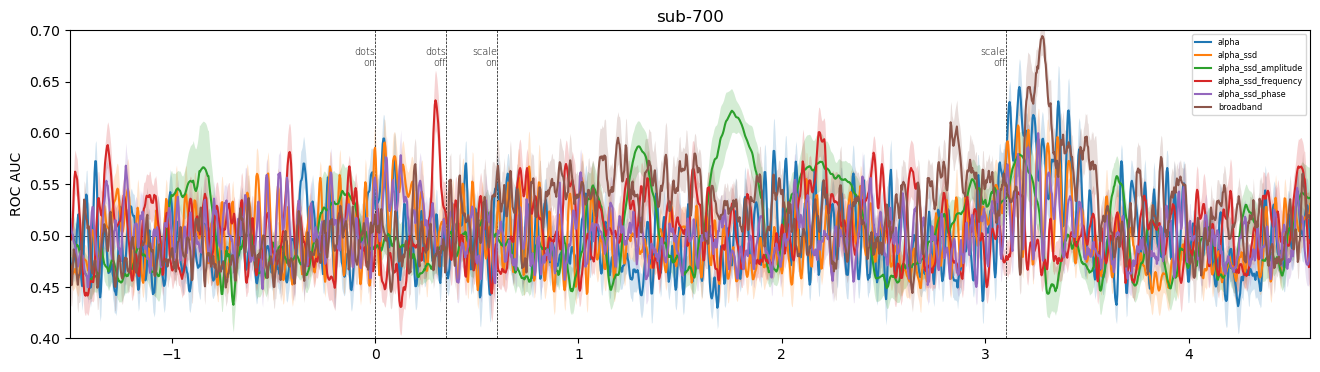

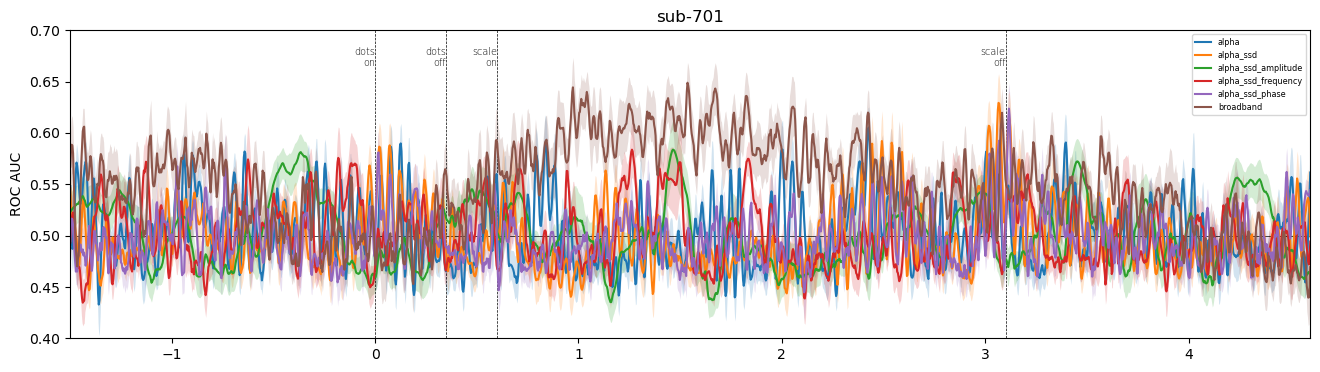

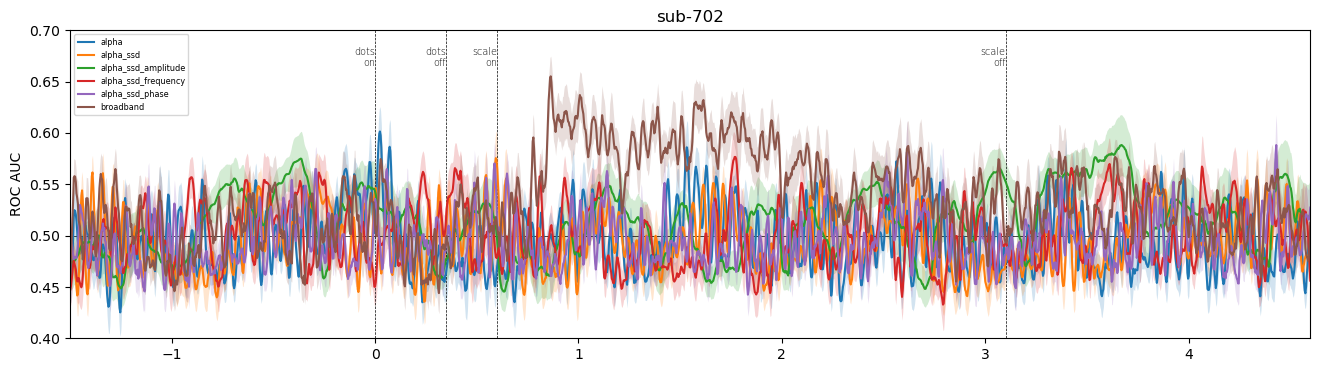

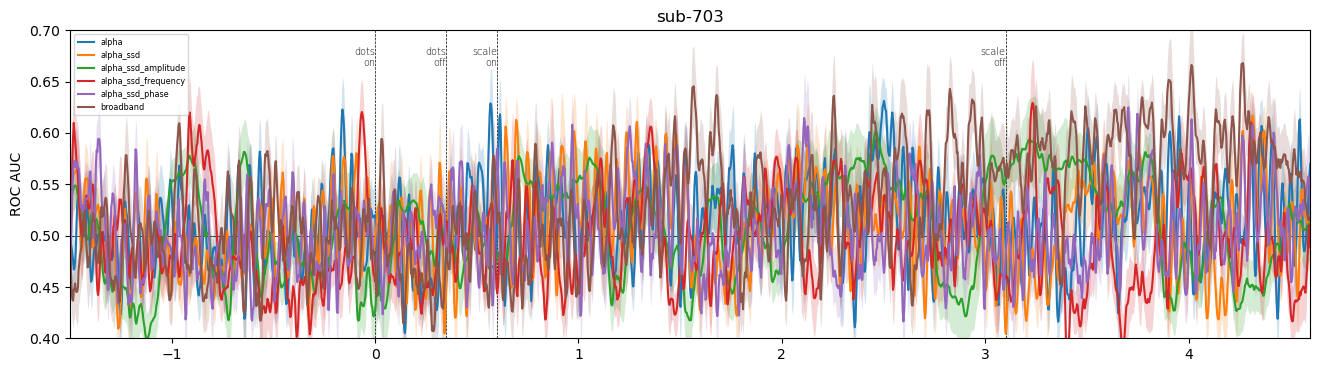

In [97]:
subjects = [i.stem for i in utils.get_directories(proc_path, depth="one")]

class_paths = {}
for subject in subjects:
    paths = utils.get_files(
        proc_path, 
        "*.npy", 
        strings=[
            "scores-binary_confidence-classify_binary_cv",
            subject
        ]
    )
    

    f, ax = plt.subplots(1, 1, figsize=(16, 4))
    ax.set_title(subject)
    ax.set_ylabel("ROC AUC")
    ax.axhline(0.5, lw=0.5, color="black")
    ax.set_xlim(epochs.times[[0, -1]])
    ymax = 0.7
    ax.set_ylim(0.40, ymax)
    for i in event_timing.keys():
        ax.axvline(i, lw=0.5, c="black", linestyle="dashed")
        ax.text(i, ymax - (ymax*0.05), event_timing[i], ha="right", weight="ultralight", size=7)
    
    for pix, path in enumerate(paths):
        data = np.load(path)
        mean = np.mean(data, axis=0)
        sem = np.std(data, axis=0) / np.sqrt(data.shape[0])
        label = path.stem.split("-")[-3]
        wl = 10
        sv_mean = savgol_filter(mean, window_length=wl, polyorder=3)
        sv_sem = savgol_filter(sem, window_length=wl, polyorder=3)
        ax.plot(time, sv_mean, lw=1.5, color=colours[pix], label=label)
        ax.fill_between(time, sv_mean - sv_sem, sv_mean + sv_sem, lw=0, color=colours[pix], alpha=0.2)
    ax.legend(fontsize="xx-small")
    


In [ ]:


class_paths = {}
for subject in subjects:
    paths = utils.get_files(
        proc_path, 
        "*.npy", 
        strings=[
            "scores-binary_confidence-classify_binary_cv",
            subject
        ]
    )
    

    f, ax = plt.subplots(1, 1, figsize=(16, 4))
    ax.set_title(subject)
    ax.set_ylabel("ROC AUC")
    ax.axhline(0.5, lw=0.5, color="black")
    ax.set_xlim(epochs.times[[0, -1]])
    ymax = 0.7
    ax.set_ylim(0.40, ymax)
    for i in event_timing.keys():
        ax.axvline(i, lw=0.5, c="black", linestyle="dashed")
        ax.text(i, ymax - (ymax*0.05), event_timing[i], ha="right", weight="ultralight", size=7)
    
    for pix, path in enumerate(paths):
        data = np.load(path)
        mean = np.mean(data, axis=0)
        sem = np.std(data, axis=0) / np.sqrt(data.shape[0])
        label = path.stem.split("-")[-3]
        wl = 20
        sv_mean = savgol_filter(mean, window_length=wl, polyorder=3)
        sv_sem = savgol_filter(sem, window_length=wl, polyorder=3)
        ax.plot(time, sv_mean, lw=1.5, color=colours[pix], label=label)
        ax.fill_between(time, sv_mean - sv_sem, sv_mean + sv_sem, lw=0, color=colours[pix], alpha=0.2)
    ax.legend(fontsize="xx-small")


'alpha'

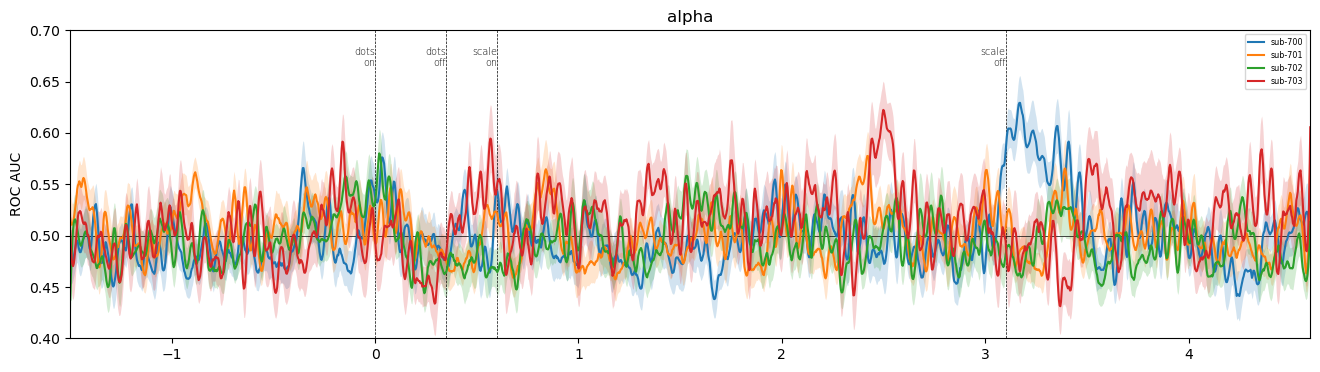

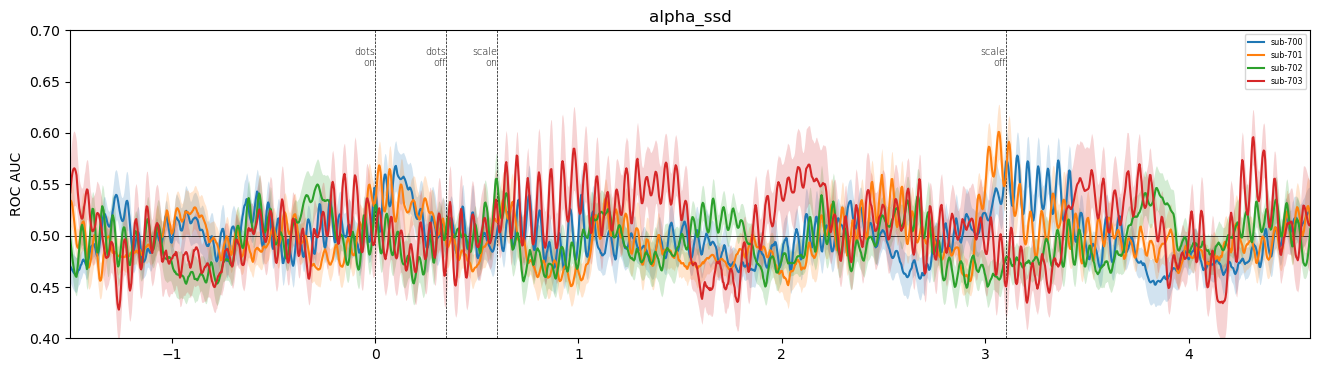

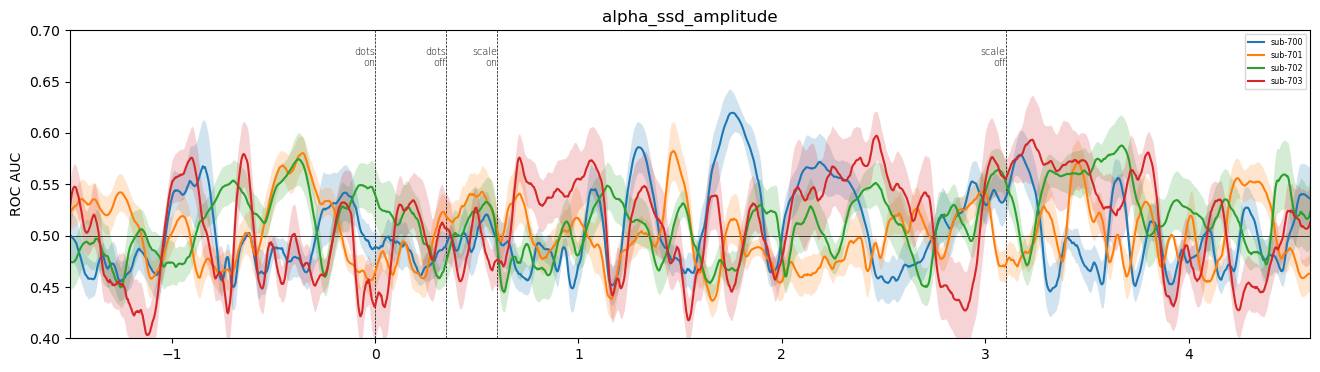

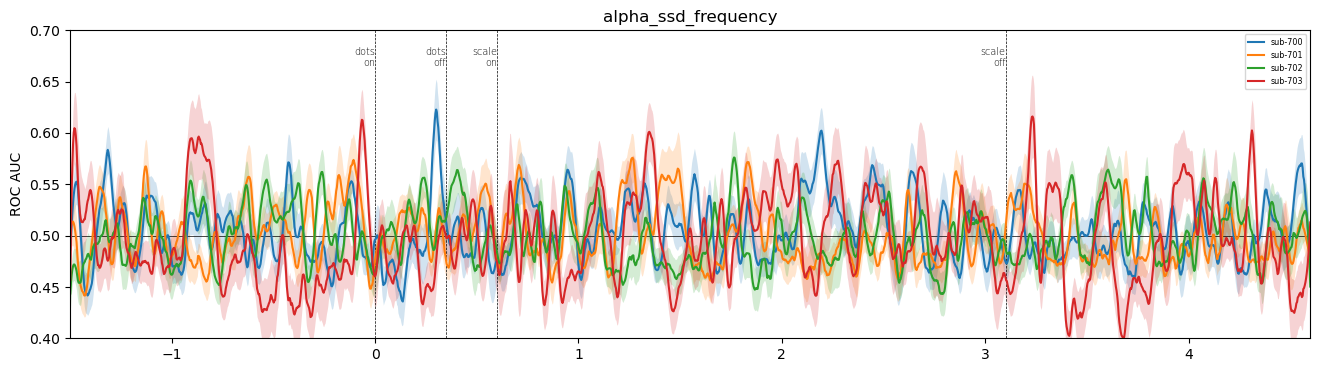

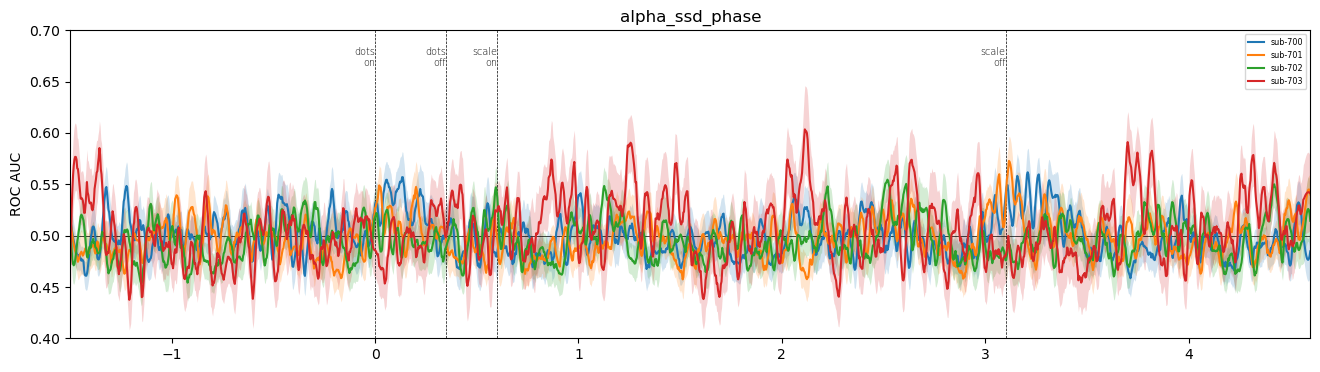

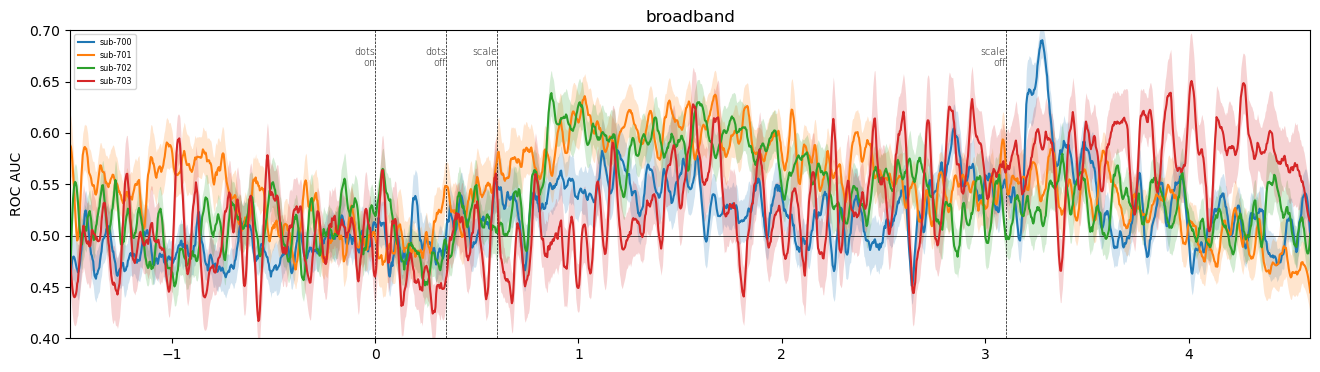

In [98]:
paths = utils.get_files(
    proc_path, 
    "*.npy", 
    strings=[
        "scores-binary_confidence-classify_binary_cv"
    ]
)
labels = np.unique([i.stem.split("-")[-3] for i in paths])
subjects = [i.stem for i in utils.get_directories(proc_path, depth="one")]


for labs in labels:
    f, ax = plt.subplots(1, 1, figsize=(16, 4))
    ax.set_title(labs)
    ax.set_ylabel("ROC AUC")
    ax.axhline(0.5, lw=0.5, color="black")
    ax.set_xlim(epochs.times[[0, -1]])
    ymax = 0.7
    ax.set_ylim(0.40, ymax)
    for i in event_timing.keys():
        ax.axvline(i, lw=0.5, c="black", linestyle="dashed")
        ax.text(i, ymax - (ymax*0.05), event_timing[i], ha="right", weight="ultralight", size=7)
    
    for sub_ix, subject in enumerate(subjects):
        path = [p for p in paths if utils.check_many([labs, subject], p.stem, func="all")][0]
        # print(labs, path)
        data = np.load(path)
        mean = np.mean(data, axis=0)
        sem = np.std(data, axis=0) / np.sqrt(data.shape[0])
        label = path.stem.split("-")[-3]
        wl = 20
        sv_mean = savgol_filter(mean, window_length=wl, polyorder=3)
        sv_sem = savgol_filter(sem, window_length=wl, polyorder=3)
        ax.plot(time, sv_mean, lw=1.5, color=colours[sub_ix], label=subject)
        ax.fill_between(time, sv_mean - sv_sem, sv_mean + sv_sem, lw=0, color=colours[sub_ix], alpha=0.2)
    ax.legend(fontsize="xx-small")

PosixPath('/home/maciek/data/counterfactual_dots/offline_dev/MEG/processed/sub-703/scores-binary_confidence-classify_binary_cv-broadband-sub-703.npy')

In [81]:
subject

'sub-703'